# Train weather → coordinates → nearest Japanese prefecture

Run the cells from top to bottom. Edit the settings cell for paths, dates and training parameters.

This LSTM uses **weather only** to reconstruct latitude/longitude for each labelled date. Coordinates are training targets, never input features. Japan's GIS boundaries turn the predicted position into `nearest_prefecture`. Risk classification is in the second notebook.

The original uploaded trajectory model needs observed coordinates and is not reused. This is an experimental reconstruction model, not evidence that town weather uniquely identifies a typhoon. The supplied 2021–January 2025 data has 75 event rows, not every calendar date.

## 1. Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "training":
    ROOT = ROOT.parent
elif (ROOT / "Typhoon" / "training").is_dir():
    ROOT = ROOT / "Typhoon"
TRAINING_DIR = ROOT / "training"
EXPERIMENT_ID = "baseline_v1"
DATA_PATH = ROOT / "data/processed/jma_day3_to_landfall_with_weather_prefecture.csv"
SHAPEFILE = ROOT / "data/gis/jp_shp/jp.shp"
OUTPUT_DIR = TRAINING_DIR / "trained_models/nearest_prefecture" / EXPERIMENT_ID
LOG_DIR = TRAINING_DIR / "experiment_logs/nearest_prefecture" / EXPERIMENT_ID

START_DATE = "2021-01-01"
END_DATE = "2025-01-31"
LOOKBACK = 3
EPOCHS = 30
BATCH_SIZE = 16
LSTM_UNITS = 32
DENSE_UNITS = 16
LEARNING_RATE = 0.001
TEST_SIZE = 0.20
FOLDS = 3
SEED = 42
REMOVE_WEATHER = []  # e.g. ["rain_sum"]
OVERWRITE_OUTPUTS = False  # use a new output directory for each experiment


## 2. Imports

In [2]:
# If needed, install once in your notebook environment:
# %pip install pandas numpy matplotlib scikit-learn geopandas shapely pyproj tensorflow joblib
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import joblib
import tensorflow as tf
from tensorflow import keras
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from shapely.geometry import Point
from shapely.ops import nearest_points
from pyproj import Geod

keras.utils.set_random_seed(SEED)
assert LOOKBACK >= 1 and EPOCHS >= 1 and BATCH_SIZE >= 1 and FOLDS >= 2
assert 0 < TEST_SIZE < 1
if not DATA_PATH.is_file() or not SHAPEFILE.is_file():
    raise FileNotFoundError("Set DATA_PATH and SHAPEFILE to your existing Typhoon files.")
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()) and not OVERWRITE_OUTPUTS:
    raise FileExistsError("Choose a new OUTPUT_DIR, or set OVERWRITE_OUTPUTS=True for this experiment.")
if LOG_DIR.exists() and any(LOG_DIR.iterdir()) and not OVERWRITE_OUTPUTS:
    raise FileExistsError("Choose a new EXPERIMENT_ID, or enable OVERWRITE_OUTPUTS.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)


I0000 00:00:1791883931.407174    7150 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791883932.511571    7150 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 3. Load the labelled historical weather

In [3]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()
df = df[df["date"].between(START_DATE, END_DATE)].copy()
df = df.sort_values(["landfall_event_id", "date"]).reset_index(drop=True)
required = {"intl_id", "landfall_event_id", "date", "latitude", "longitude", "risk"}
if not required.issubset(df.columns) or df.empty:
    raise ValueError(f"Need labelled event rows with columns {sorted(required)} in the chosen period.")
if df[list(required)].isna().any().any():
    raise ValueError("Dates, event IDs, storm IDs, coordinates and risk labels cannot be missing.")
if df.duplicated(["landfall_event_id", "date"]).any():
    raise ValueError("More than one row for the same event/date; resolve this before training.")
if (df.groupby("landfall_event_id")["intl_id"].nunique() != 1).any():
    raise ValueError("Each landfall event must belong to one storm.")
print(f"{len(df)} rows | {df.date.nunique()} dates | {df.landfall_event_id.nunique()} events | {df.intl_id.nunique()} storms")
display(df[["date", "storm_name", "latitude", "longitude", "risk"]].head())
display(df["risk"].value_counts().rename("rows"))


75 rows | 42 dates | 19 events | 10 storms


,date,storm_name,latitude,longitude,risk
0,2021-07-24,NEPARTAK,28.4,150.6,Low
1,2021-07-25,NEPARTAK,32.8,149.3,Moderate
2,2021-07-26,NEPARTAK,34.3,142.9,High
3,2021-07-27,NEPARTAK,38.2,141.7,High
4,2021-08-05,LUPIT,24.0,117.5,Low


risk
High        38
Moderate    19
Low         18
Name: rows, dtype: int64

## 4. Weather inputs and daily sequences
Each window ends on its target date. Events are kept separate; windows cannot cross missing days. Early event rows use a **masked** shorter history, so Low and Moderate rows are retained without inventing preceding weather.

In [4]:
WEATHER = ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'dew_point_2m_max', 'dew_point_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'cloud_cover_mean', 'cloud_cover_max', 'cloud_cover_min', 'pressure_msl_mean', 'pressure_msl_max', 'pressure_msl_min', 'surface_pressure_mean', 'surface_pressure_max', 'surface_pressure_min', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_speed_10m_min', 'wind_gusts_10m_mean', 'wind_gusts_10m_max', 'wind_gusts_10m_min', 'wind_direction_10m_dominant', 'shortwave_radiation_sum']
unknown = set(REMOVE_WEATHER) - set(WEATHER)
if unknown:
    raise ValueError(f"Unknown weather names: {sorted(unknown)}")
WEATHER = [c for c in WEATHER if c not in REMOVE_WEATHER]
if not WEATHER:
    raise ValueError("Keep at least one weather input.")
missing = set(WEATHER) - set(df.columns)
if missing:
    raise ValueError(f"Missing weather inputs: {sorted(missing)}")
encoded = df[WEATHER].apply(pd.to_numeric, errors="raise").copy()
if "wind_direction_10m_dominant" in encoded:
    angle = np.deg2rad(encoded.pop("wind_direction_10m_dominant"))
    encoded["wind_direction_sin"], encoded["wind_direction_cos"] = np.sin(angle), np.cos(angle)
angle = 2 * np.pi * (df.date.dt.dayofyear - 1) / 365.25
encoded["calendar_sin"], encoded["calendar_cos"] = np.sin(angle), np.cos(angle)
FEATURES = encoded.columns.tolist()
raw = encoded.to_numpy(dtype="float32")
if np.isinf(raw).any():
    raise ValueError("Weather inputs contain infinite values.")

X = np.full((len(df), LOOKBACK, len(FEATURES)), np.nan, dtype="float32")
valid_steps = np.zeros((len(df), LOOKBACK), dtype=bool)
for _, event in df.groupby("landfall_event_id", sort=False):
    history = []
    previous_day = None
    for row_id in event.index:
        day = df.loc[row_id, "date"]
        if previous_day is not None and day - previous_day != pd.Timedelta(days=1):
            history = []
        history = (history + [row_id])[-LOOKBACK:]
        X[row_id, -len(history):] = raw[history]
        valid_steps[row_id, -len(history):] = True
        previous_day = day
y = df[["latitude", "longitude"]].to_numpy(dtype="float32")
if not np.isfinite(y).all() or (np.abs(y[:, 0]) > 90).any() or (np.abs(y[:, 1]) > 180).any():
    raise ValueError("Invalid historical coordinate targets.")
print("Weather features:", FEATURES)
print("X:", X.shape, "y:", y.shape)
print("Latitude/longitude inputs: excluded")


Weather features: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'dew_point_2m_max', 'dew_point_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'cloud_cover_mean', 'cloud_cover_max', 'cloud_cover_min', 'pressure_msl_mean', 'pressure_msl_max', 'pressure_msl_min', 'surface_pressure_mean', 'surface_pressure_max', 'surface_pressure_min', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_speed_10m_min', 'wind_gusts_10m_mean', 'wind_gusts_10m_max', 'wind_gusts_10m_min', 'shortwave_radiation_sum', 'wind_direction_sin', 'wind_direction_cos', 'calendar_sin', 'calendar_cos']
X: (75, 3, 32) y: (75, 2)
Latitude/longitude inputs: excluded


## 5. Hold out whole storms
The same split is passed to the classifier notebook, so its test storms are excluded from both models.

In [5]:
groups = df["intl_id"].astype(str).to_numpy()
if len(np.unique(groups)) < 4:
    raise ValueError("Need at least four independent storms for holdout and cross-fitting.")
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED).split(X, groups=groups))
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
print(f"Train: {len(train_idx)} rows, {len(np.unique(groups[train_idx]))} storms")
print(f"Test:  {len(test_idx)} rows, {len(np.unique(groups[test_idx]))} storms")


Train: 63 rows, 8 storms
Test:  12 rows, 2 storms


## 6. Build and train the coordinate LSTM
Preprocessing is fitted only on each training subset. Masked time steps are ignored by the LSTM. The displayed loss is coordinate regression loss, not classification accuracy.

In [6]:
MASK_VALUE = -999.0

def transform_windows(indices, preprocess):
    result = np.full(X[indices].shape, MASK_VALUE, dtype="float32")
    mask = valid_steps[indices]
    observed = X[indices][mask]
    result[mask] = preprocess["x_scaler"].transform(preprocess["imputer"].transform(observed))
    if not np.isfinite(result).all() or np.any(np.all(result[mask] == MASK_VALUE, axis=1)):
        raise ValueError("Invalid scaled inputs or masking collision.")
    return result


def train_coordinate_model(indices, seed=SEED, verbose=0):
    keras.utils.set_random_seed(seed)
    observed = X[indices][valid_steps[indices]]
    imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(observed)
    preprocess = {
        "imputer": imputer,
        "x_scaler": StandardScaler().fit(imputer.transform(observed)),
        "y_scaler": StandardScaler().fit(y[indices]),
    }
    model = keras.Sequential([
        keras.layers.Input(shape=(LOOKBACK, len(FEATURES))),
        keras.layers.Masking(mask_value=MASK_VALUE),
        keras.layers.LSTM(LSTM_UNITS),
        keras.layers.Dense(DENSE_UNITS, activation="relu"),
        keras.layers.Dense(2, name="reconstructed_lat_lon"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    xx = transform_windows(indices, preprocess)
    yy = preprocess["y_scaler"].transform(y[indices]).astype("float32")
    dataset = tf.data.Dataset.from_tensor_slices((xx, yy)).shuffle(len(indices), seed=seed).batch(BATCH_SIZE)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    dataset = dataset.with_options(options)
    history = model.fit(dataset, epochs=EPOCHS, verbose=verbose)
    return model, preprocess, history


def predict_coordinates(indices, model, preprocess):
    scaled = model(transform_windows(indices, preprocess), training=False).numpy()
    coords = preprocess["y_scaler"].inverse_transform(scaled)
    if not np.isfinite(coords).all() or (np.abs(coords[:, 0]) > 90).any() or (np.abs(coords[:, 1]) > 180).any():
        raise ValueError("Predictions are not valid coordinates; inspect training settings/data.")
    return coords


## 7. Reconstruct training rows and heldout rows
Training rows use predictions from models that did not train on those storms (out-of-fold). This prevents the classifier from learning from an unrealistically easy coordinate reconstruction. Test rows use the final model trained on training storms only.

Reconstructing training fold 1/3


E0000 00:00:1791883934.433289    7150 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Reconstructing training fold 2/3


Reconstructing training fold 3/3


Training the final coordinate model
Epoch 1/30


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_3 (Masking)             │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_lat_lon (Dense)   │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,648 (104.10 KB)

 Trainable params: 8,882 (34.70 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 17,766 (69.40 KB)

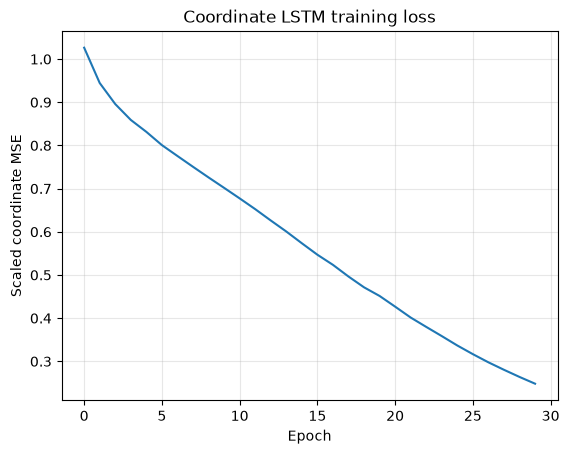

In [7]:
predicted_coordinates = np.empty_like(y)
fold_count = min(FOLDS, len(np.unique(groups[train_idx])))
if fold_count < 2:
    raise ValueError("Need at least two training storms for cross-fitting.")
for fold, (fit, validation) in enumerate(GroupKFold(n_splits=fold_count).split(X[train_idx], groups=groups[train_idx])):
    print(f"Reconstructing training fold {fold + 1}/{fold_count}")
    fold_model, fold_preprocess, _ = train_coordinate_model(train_idx[fit], seed=SEED + fold)
    predicted_coordinates[train_idx[validation]] = predict_coordinates(train_idx[validation], fold_model, fold_preprocess)

print("Training the final coordinate model")
model, preprocess, history = train_coordinate_model(train_idx, verbose=2)
model.summary()
predicted_coordinates[test_idx] = predict_coordinates(test_idx, model, preprocess)
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Scaled coordinate MSE")
plt.title("Coordinate LSTM training loss")
plt.grid(alpha=0.3)
plt.savefig(LOG_DIR / "training_loss.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Convert predicted coordinates to Japanese prefectures

In [8]:
prefectures = gpd.read_file(SHAPEFILE)
if prefectures.crs is None:
    raise ValueError("Japan shapefile needs a coordinate reference system.")
prefectures = prefectures.to_crs("EPSG:4326")
if len(prefectures) != 47 or "name" not in prefectures:
    raise ValueError("Use Japan's jp.shp with 47 prefectures and a name column.")
if prefectures.geometry.isna().any() or not prefectures.geometry.is_valid.all():
    raise ValueError("Missing or invalid prefecture geometries.")

def clean_name(name):
    try:
        return str(name).encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return str(name)

geod = Geod(ellps="WGS84")
def nearest_prefecture(coordinates):
    names, distances = [], []
    for latitude, longitude in coordinates:
        point = Point(float(longitude), float(latitude))
        candidates = []
        for geometry in prefectures.geometry:
            closest = nearest_points(point, geometry)[1]
            distance = 0.0 if geometry.covers(point) else abs(geod.inv(point.x, point.y, closest.x, closest.y)[2]) / 1000
            candidates.append(distance)
        index = int(np.argmin(candidates))
        names.append(clean_name(prefectures.iloc[index]["name"]))
        distances.append(candidates[index])
    return np.asarray(names), np.asarray(distances)

predicted_prefectures, distances = nearest_prefecture(predicted_coordinates)
actual_prefectures, _ = nearest_prefecture(y)


## 9. View heldout results

,value
test_rows,12.000000
latitude_MAE_degrees,4.346789
longitude_MAE_degrees,10.744835
mean_location_error_km,1175.776132
nearest_prefecture_accuracy,0.083333


,date,storm_name,risk,actual_latitude,actual_longitude,predicted_latitude,predicted_longitude,actual_nearest_prefecture,predicted_nearest_prefecture
0,2021-08-05,LUPIT,Low,24.000000,117.500000,30.482002,132.314835,Okinawa,Kagoshima
1,2021-08-06,LUPIT,Moderate,25.100000,120.000000,29.634037,132.680267,Okinawa,Kagoshima
2,2021-08-07,LUPIT,High,28.299999,125.800003,29.435432,130.731720,Okinawa,Kagoshima
3,2021-08-08,LUPIT,High,31.299999,130.399994,29.891153,128.172668,Kagoshima,Kagoshima
4,2021-08-05,LUPIT,Low,24.000000,117.500000,30.482002,132.314835,Okinawa,Kagoshima
5,2021-08-06,LUPIT,Moderate,25.100000,120.000000,29.634037,132.680267,Okinawa,Kagoshima
6,2021-08-07,LUPIT,High,28.299999,125.800003,29.435432,130.731720,Okinawa,Kagoshima
7,2021-08-08,LUPIT,High,34.400002,132.500000,29.824093,132.244125,Hiroshima,Kagoshima
8,2024-08-08,MARIA,Low,29.799999,145.600006,28.411518,131.055740,Tokyo,Okinawa
9,2024-08-09,MARIA,Moderate,34.200001,146.000000,28.744780,128.963455,Chiba,Okinawa


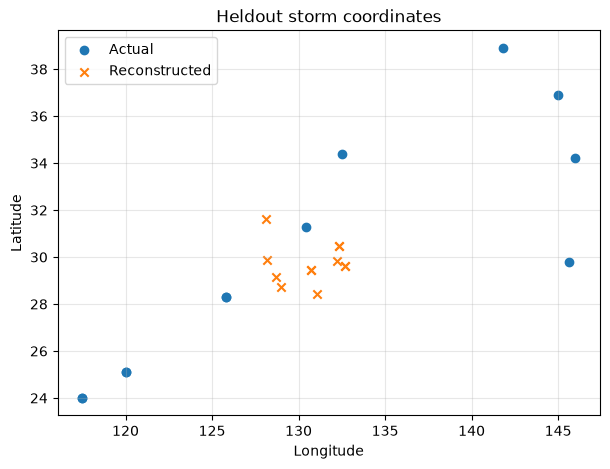

In [9]:
_, _, error_metres = geod.inv(y[test_idx, 1], y[test_idx, 0], predicted_coordinates[test_idx, 1], predicted_coordinates[test_idx, 0])
metrics = pd.Series({
    "test_rows": len(test_idx),
    "latitude_MAE_degrees": np.abs(y[test_idx, 0] - predicted_coordinates[test_idx, 0]).mean(),
    "longitude_MAE_degrees": np.abs(y[test_idx, 1] - predicted_coordinates[test_idx, 1]).mean(),
    "mean_location_error_km": np.abs(error_metres).mean() / 1000,
    "nearest_prefecture_accuracy": (predicted_prefectures[test_idx] == actual_prefectures[test_idx]).mean(),
})
display(metrics.to_frame("value"))
results = df.iloc[test_idx][["date", "storm_name", "risk"]].reset_index(drop=True)
results[["actual_latitude", "actual_longitude"]] = y[test_idx]
results[["predicted_latitude", "predicted_longitude"]] = predicted_coordinates[test_idx]
results["actual_nearest_prefecture"] = actual_prefectures[test_idx]
results["predicted_nearest_prefecture"] = predicted_prefectures[test_idx]
display(results.head(12))
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y[test_idx, 1], y[test_idx, 0], label="Actual", marker="o")
ax.scatter(predicted_coordinates[test_idx, 1], predicted_coordinates[test_idx, 0], label="Reconstructed", marker="x")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Heldout storm coordinates")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(LOG_DIR / "heldout_coordinates.png", dpi=120, bbox_inches="tight")
plt.show()


## 10. Save the model and merged training file
The merged file retains each original event/date and weather row, adds reconstructed coordinates and prefecture, and carries the train/test split into notebook 2. No date-only merge is needed: simultaneous events remain separate. No labels are invented for dates absent from the event dataset.

In [10]:
merged = df.copy()
merged["observed_latitude"], merged["observed_longitude"] = df.latitude, df.longitude
merged["observed_nearest_prefecture"] = actual_prefectures
merged["latitude"], merged["longitude"] = predicted_coordinates[:, 0], predicted_coordinates[:, 1]
merged["nearest_prefecture"] = predicted_prefectures
merged["distance_to_prefecture_km"] = distances
merged["split"] = "train"
merged.loc[test_idx, "split"] = "test"
merged["location_prediction_source"] = "out_of_fold"
merged.loc[test_idx, "location_prediction_source"] = "heldout"
merged["year"], merged["month"], merged["day"] = merged.date.dt.year, merged.date.dt.month, merged.date.dt.day
MERGED_PATH = OUTPUT_DIR / "reconstructed_weather_prefecture.csv"
merged.to_csv(MERGED_PATH, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
model.save(OUTPUT_DIR / "weather_to_coordinates.keras")
joblib.dump(preprocess, OUTPUT_DIR / "preprocessing.joblib")
config = {"features": FEATURES, "weather": WEATHER, "lookback": LOOKBACK, "mask_value": MASK_VALUE,
          "start_date": START_DATE, "end_date": END_DATE, "epochs": EPOCHS, "test_storms": sorted(set(groups[test_idx])),
          "target": ["latitude", "longitude"], "target_date_weather_included": True}
(OUTPUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
metrics.to_csv(OUTPUT_DIR / "coordinate_metrics.csv", header=["value"])
results.to_csv(OUTPUT_DIR / "heldout_predictions.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
print("Merged file for notebook 2:", MERGED_PATH)
print("Saved model and results:", OUTPUT_DIR)
display(merged[["date", "nearest_prefecture", "latitude", "longitude", "risk", "split"]].head())

(LOG_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
pd.DataFrame(history.history).to_csv(LOG_DIR / "training_history.csv", index=False)
metrics.to_csv(LOG_DIR / "coordinate_metrics.csv", header=["value"])
print("Experiment logs:", LOG_DIR)


Merged file for notebook 2: /workspace/Project-Innovation/Typhoon/training/trained_models/nearest_prefecture/baseline_v1/reconstructed_weather_prefecture.csv
Saved model and results: /workspace/Project-Innovation/Typhoon/training/trained_models/nearest_prefecture/baseline_v1


,date,nearest_prefecture,latitude,longitude,risk,split
0,2021-07-24,Wakayama,30.430645,136.237915,Low,train
1,2021-07-25,Tokyo,30.954996,137.026230,Moderate,train
2,2021-07-26,Wakayama,31.512554,137.157562,High,train
3,2021-07-27,Wakayama,31.770090,136.709183,High,train
4,2021-08-05,Kagoshima,30.482002,132.314835,Low,test


Experiment logs: /workspace/Project-Innovation/Typhoon/training/experiment_logs/nearest_prefecture/baseline_v1
